# LangChain

In [1]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from dotenv import load_dotenv

load_dotenv()

@tool
def get_capital_of_country(country: str) -> str:
    """this is a tool that returns the capital of a given country"""
    capitals = {
        "France": "Neverland",
        "Germany": "Berlin",
        "Italy": "Rome",
        "Spain": "Madrid",
        "United Kingdom": "Hogwarts",
    }
    return capitals.get(country, "Unknown")

model = init_chat_model(model="gpt-4o", model_provider="openai")

query = "What is the capital of United Kingdom?"

agent = create_agent(model=model, tools=[get_capital_of_country])   

response = agent.invoke({"messages": [query]})

messsage_history = response["messages"]
new_query = "What is the capital of France?"

new_response = agent.invoke({"messages": messsage_history + [new_query]})

for message in new_response["messages"]:
    if message.type == "human":
        pending_user = message.content
    elif message.type == "ai" and pending_user is not None and not message.tool_calls:
        print({
            "user_input": pending_user,
            "agent_output": message.content,
        })
        pending_user = None

{'user_input': 'What is the capital of United Kingdom?', 'agent_output': 'The capital of the United Kingdom is London.'}
{'user_input': 'What is the capital of France?', 'agent_output': 'The capital of France is Paris.'}


# LangGraph

{'user_input': 'What is the capital of United Kingdom?', 'agent_output': 'The capital of the United Kingdom is Hogwarts.'}


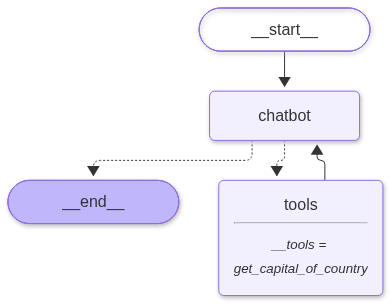

In [2]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
from IPython.display import Image, display


load_dotenv()

model = init_chat_model(model="gpt-4o", model_provider="openai")

@tool
def get_capital_of_country(country: str) -> str:
    """this is a tool that returns the capital of a given country"""
    capitals = {
        "France": "Neverland",
        "Germany": "Berlin",
        "Italy": "Rome",
        "Spain": "Madrid",
        "United Kingdom": "Hogwarts",
    }
    return capitals.get(country, "Unknown")

tools = [get_capital_of_country]

tool_node = ToolNode(tools)

model_with_tools = model.bind_tools([get_capital_of_country])

def should_continue(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"
    return END

def call_model(state: MessagesState):
    last_message = state["messages"][-1]
    if isinstance(last_message, AIMessage) and last_message.tool_calls:
        return {"messages": last_message.tool_calls[0].tool_response}
    return {"messages": model_with_tools.invoke(state["messages"])}

workflow = StateGraph(MessagesState)
workflow.add_node("chatbot", call_model)
workflow.add_node("tools", tool_node)

workflow.add_edge(START, "chatbot")
workflow.add_conditional_edges("chatbot", should_continue, ["tools", END])
workflow.add_edge("tools", "chatbot")

# compile worflow into a runnable
runnable = workflow.compile()

response = runnable.invoke({"messages": [HumanMessage(content="What is the capital of United Kingdom?")]})

print({
    "user_input": response["messages"][0].content,
    "agent_output": response["messages"][-1].content,
})

display(Image(data=runnable.get_graph().draw_mermaid_png()))
